# AdaFace — Reconocimiento facial con margen adaptativo a la calidad

Este cuaderno muestra, paso a paso, cómo usar **AdaFace** para **verificar identidades a partir de rostros**: dadas dos fotos, decidir si corresponden o no a la misma persona. Es un buen ejemplo de un sistema moderno de reconocimiento facial de extremo a extremo.

La tubería completa es:

1. **Detección y alineamiento** del rostro (con MTCNN): se recorta la cara y se la lleva a un tamaño y orientación canónicos (112×112).
2. **Extracción del *embedding*** (con AdaFace): la red convierte el rostro en un vector de 512 números que resume la identidad.
3. **Comparación**: se mide la **similitud coseno** entre dos *embeddings*. Cuanto más cercana a 1, más parecidos; cuanto más cercana a 0 (o negativa), más distintos.

### ¿Qué tiene de especial AdaFace?

El gran problema del reconocimiento facial en la práctica es la **calidad dispar** de las imágenes: hay fotos nítidas y de frente, y otras borrosas, de perfil o mal iluminadas. Forzar a la red a "acertar" sobre una cara casi irreconocible la empuja a aprender ruido. AdaFace introduce un **margen adaptativo a la calidad**: usa la **norma del *embedding*** como indicador de calidad de la imagen y ajusta cuánto exige según ese valor —es más estricto con las fotos buenas y más indulgente con las malas—. Eso lo hace notablemente robusto. Esa idea la veremos en acción más abajo, en el experimento de degradación.

> **Referencia.** Kim, M., Jain, A. K., & Liu, X. (2022). *AdaFace: Quality Adaptive Margin for Face Recognition*. CVPR 2022, pp. 18750–18759. [[paper]](https://openaccess.thecvf.com/content/CVPR2022/papers/Kim_AdaFace_Quality_Adaptive_Margin_for_Face_Recognition_CVPR_2022_paper.pdf)

---
*Traducido, adaptado y ampliado por Diego — material docente del curso de Visión por Computadora (Pontificia Universidad Católica de Chile). Basado en el cuaderno original de demostración de AdaFace.*

## 1. Repositorio y modelo preentrenado

Clonamos el repositorio oficial de AdaFace y descargamos los pesos del modelo `ir_50` (entrenado sobre MS1MV2). También instalamos MTCNN (para detectar y alinear rostros) y PyTorch Lightning (formato en que viene guardado el *checkpoint*).

In [ ]:
# Clonamos el repositorio oficial de AdaFace
!git clone https://github.com/mk-minchul/AdaFace

# Creamos la carpeta donde irán los pesos preentrenados
!mkdir -p /content/AdaFace/pretrained

# Descargamos el checkpoint del modelo ir_50 (entrenado en MS1MV2) desde Google Drive
!gdown https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI
!mv adaface_ir50_ms1mv2.ckpt /content/AdaFace/pretrained/adaface_ir50_ms1mv2.ckpt

# Dependencias
!pip install -q pytorch-lightning   # formato del checkpoint
!pip install -q mtcnn               # detección + alineamiento de rostros
!pip install -q opencv-contrib-python

Cloning into 'AdaFace'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 236 (delta 66), reused 56 (delta 56), pack-reused 129 (from 1)
Receiving objects: 100% (236/236), 38.95 MiB | 29.61 MiB/s, done.
Resolving deltas: 100% (88/88), done.
Downloading...
From (original): https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI
From (redirected): https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI&confirm=t&uuid=198fce09-f54b-4939-9efc-54778dedb5a8
To: /content/adaface_ir50_ms1mv2.ckpt
100% 700M/700M [00:06<00:00, 110MB/s] 
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.9 MB/s eta 0:00:00


## 2. Librerías

Cargamos las librerías base. Usaremos **OpenCV** para leer imágenes, **PyTorch** para correr el modelo, **NumPy** para los arreglos y **Matplotlib** para visualizar.

In [ ]:
import cv2
from google.colab.patches import cv2_imshow   # para mostrar imágenes BGR en Colab
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
# MTCNN: detector de rostros que además entrega los puntos para alinear la cara
from mtcnn.mtcnn import MTCNN
detector = MTCNN()

## 3. Carga del modelo AdaFace

Nos movemos a la carpeta del repositorio e importamos sus utilidades:

- `align.get_aligned_face(...)`: detecta el rostro y lo alinea a 112×112.
- `to_input(...)`: convierte la cara alineada al tensor que espera la red.
- `load_pretrained_model(...)`: carga la arquitectura `ir_50` con sus pesos.

> Nota técnica: en versiones recientes de PyTorch, `torch.load` es más estricto por seguridad. Por eso registramos `ModelCheckpoint` como *safe global* antes de cargar el *checkpoint*.

In [ ]:
%cd /content/AdaFace
from face_alignment import align
from inference import load_pretrained_model, to_input
from pytorch_lightning.callbacks import ModelCheckpoint

# Permitir la deserialización del checkpoint en versiones nuevas de PyTorch
torch.serialization.add_safe_globals([ModelCheckpoint])

# Cargamos el modelo ir_50 y lo dejamos en modo evaluación
model = load_pretrained_model('ir_50')
print('Modelo AdaFace ir_50 cargado correctamente.')

/content/AdaFace


/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:287: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if align_type is 'cv2_affine':
/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:290: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif align_type is 'affine':


Modelo AdaFace ir_50 cargado correctamente.


## 4. Funciones auxiliares

Definimos un conjunto de funciones cómodas que usaremos durante todo el cuaderno.

El modelo devuelve **dos** cosas por cada rostro: el *embedding* (vector 1×512 que identifica a la persona) y la **norma** de ese vector. En AdaFace esa norma funciona como un **indicador de la calidad** de la imagen: rostros nítidos y bien alineados tienden a producir normas más altas. La aprovecharemos más adelante.

In [ ]:
def obtener_embedding(path=None, imagen_pil=None):
    '''Detecta y alinea el rostro, y devuelve su embedding, su norma (calidad)
    y la cara alineada (PIL). Acepta una ruta de archivo o una imagen PIL.'''
    cara = align.get_aligned_face(path, rgb_pil_image=imagen_pil)
    if cara is None:
        return None, None, None
    entrada = to_input(cara)
    emb, norma = model(entrada)        # emb: 1x512   norma: calidad estimada
    return emb, norma.item(), cara


def _embedding_de_cara(cara_pil):
    '''Versión que parte de un rostro YA alineado (112x112), sin re-detectar.
    Útil para el experimento de calidad, donde queremos controlar la degradación.'''
    entrada = to_input(cara_pil)
    emb, norma = model(entrada)
    return emb, norma.item()


def similitud(emb1, emb2):
    '''Similitud coseno entre dos embeddings (1 = idénticos, 0 = sin relación).'''
    cos = nn.CosineSimilarity(dim=1, eps=1e-6)
    return cos(emb1, emb2).item()


def similitud_ada(path1, path2):
    '''Similitud coseno directa entre dos rutas de imagen.'''
    emb1, _, _ = obtener_embedding(path1)
    emb2, _, _ = obtener_embedding(path2)
    return similitud(emb1, emb2)

### Umbral de decisión y verificación

Para convertir un puntaje de similitud en una **decisión** ("misma persona" / "personas distintas") necesitamos un **umbral**. Por encima del umbral decimos que es la misma persona; por debajo, que son distintas.

El umbral correcto depende del modelo y del **punto de operación** deseado: subirlo reduce los falsos positivos (aceptar a un impostor) pero aumenta los falsos negativos (rechazar a la persona correcta), y viceversa. En un sistema real se elige a partir de una curva ROC sobre datos etiquetados. Aquí usaremos un valor **ilustrativo** que separa bien nuestros ejemplos; siéntete libre de ajustarlo.

In [ ]:
UMBRAL = 0.30   # valor ilustrativo; ajústalo según tu punto de operación

def verificar(path1, path2, umbral=UMBRAL, verboso=True):
    '''Decide si dos imágenes son de la misma persona según el umbral.'''
    s = similitud_ada(path1, path2)
    misma = s >= umbral
    veredicto = '✅ MISMA PERSONA' if misma else '❌ PERSONAS DISTINTAS'
    if verboso:
        print(f'similitud = {s:0.4f}   (umbral = {umbral})   ->   {veredicto}')
    return s, misma

### Visualización de pares

Una función para mostrar dos rostros **alineados** lado a lado, con su puntaje de similitud y el veredicto en el título.

In [ ]:
def mostrar_par(path1, path2, umbral=UMBRAL, titulo=None):
    '''Muestra dos caras alineadas lado a lado con su similitud y veredicto.'''
    emb1, n1, cara1 = obtener_embedding(path1)
    emb2, n2, cara2 = obtener_embedding(path2)
    if cara1 is None or cara2 is None:
        print('No se detectó rostro en alguna de las imágenes.')
        return
    s = similitud(emb1, emb2)
    misma = s >= umbral
    veredicto = 'MISMA PERSONA' if misma else 'PERSONAS DISTINTAS'

    fig, ax = plt.subplots(1, 2, figsize=(6, 3.4))
    ax[0].imshow(cara1); ax[0].axis('off'); ax[0].set_title(f'calidad={n1:0.1f}', fontsize=9)
    ax[1].imshow(cara2); ax[1].axis('off'); ax[1].set_title(f'calidad={n2:0.1f}', fontsize=9)
    enc = titulo or f'similitud = {s:0.4f}  →  {veredicto}'
    fig.suptitle(enc, fontsize=12, color=('green' if misma else 'firebrick'))
    plt.tight_layout()
    plt.show()
    return s

## 5. Las imágenes de prueba

El repositorio trae tres rostros de ejemplo. Los miramos primero para saber con qué trabajamos:

- **`img1.jpeg`** y **`img2.jpeg`**: dos fotos de **Robert Downey Jr.** (una más joven y afeitada, otra con barba) → servirán como **par genuino** (misma persona).
- **`img3.jpeg`**: **Nicolas Cage** → servirá como **par impostor** (persona distinta) al compararlo con los anteriores.

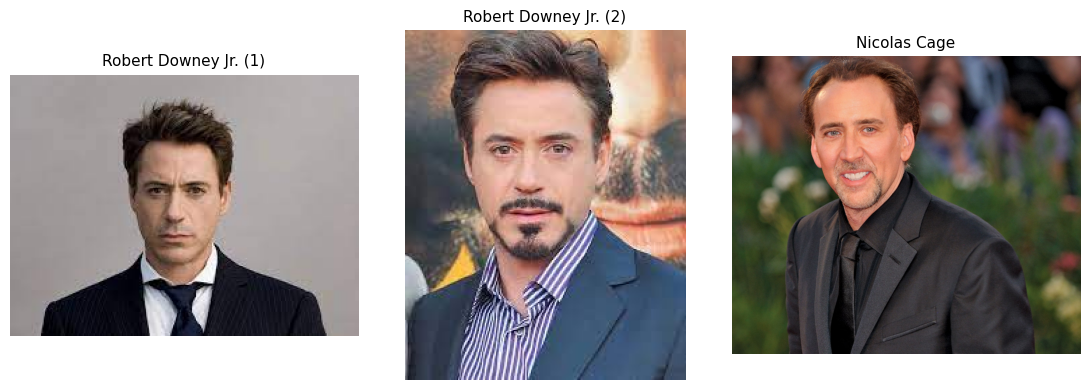

In [ ]:
rutas = {
    'Robert Downey Jr. (1)': 'face_alignment/test_images/img1.jpeg',
    'Robert Downey Jr. (2)': 'face_alignment/test_images/img2.jpeg',
    'Nicolas Cage'         : 'face_alignment/test_images/img3.jpeg',
}

# Mostramos las imágenes originales
fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, (nombre, ruta) in zip(ax, rutas.items()):
    img_rgb = cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
    a.imshow(img_rgb); a.axis('off'); a.set_title(nombre, fontsize=11)
plt.tight_layout(); plt.show()

Y así se ven una vez **detectadas y alineadas** por MTCNN (lo que realmente "ve" la red): recortadas, centradas y llevadas a 112×112. Bajo cada una aparece su **norma/calidad** estimada por AdaFace.

/content/AdaFace/inference.py:25: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  tensor = torch.tensor([brg_img.transpose(2,0,1)]).float()


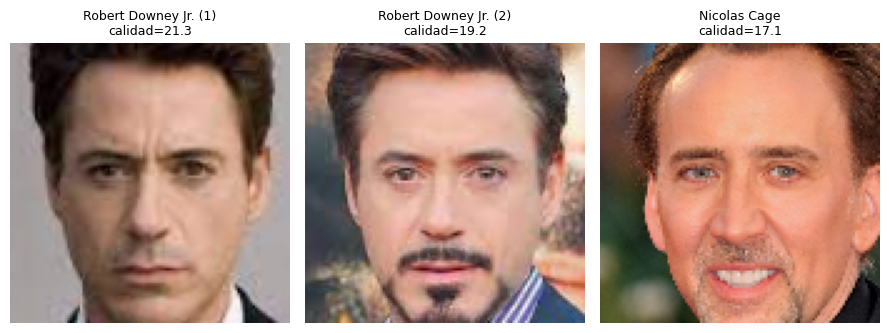

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3.6))
for a, (nombre, ruta) in zip(ax, rutas.items()):
    _, norma, cara = obtener_embedding(ruta)
    a.imshow(cara); a.axis('off')
    a.set_title(f'{nombre}\ncalidad={norma:0.1f}', fontsize=9)
plt.tight_layout(); plt.show()

## 6. Par genuino

Dos imágenes de la **misma persona** (Robert Downey Jr.). Esperamos una similitud **alta**, por encima del umbral.

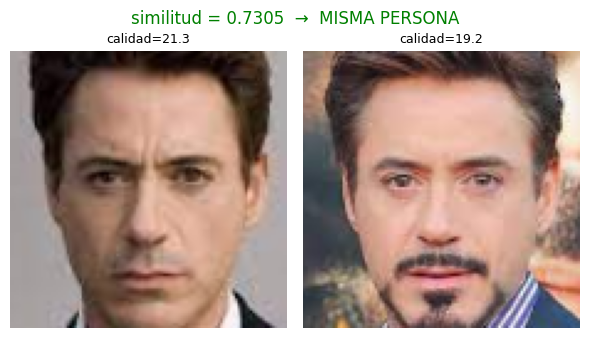

similitud = 0.7305   (umbral = 0.3)   ->   ✅ MISMA PERSONA


In [ ]:
img1 = 'face_alignment/test_images/img1.jpeg'
img2 = 'face_alignment/test_images/img2.jpeg'
img3 = 'face_alignment/test_images/img3.jpeg'

mostrar_par(img1, img2)
verificar(img1, img2);

## 7. Par impostor

Una imagen de **una persona** comparada con la de **otra distinta** (Robert Downey Jr. vs Nicolas Cage). Esperamos una similitud **baja**, por debajo del umbral.

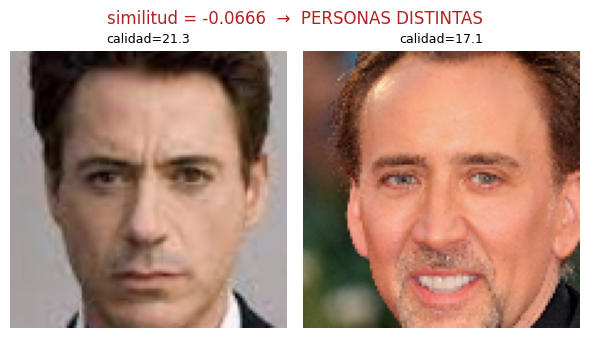

similitud = -0.0666   (umbral = 0.3)   ->   ❌ PERSONAS DISTINTAS


In [ ]:
mostrar_par(img1, img3)
verificar(img1, img3);

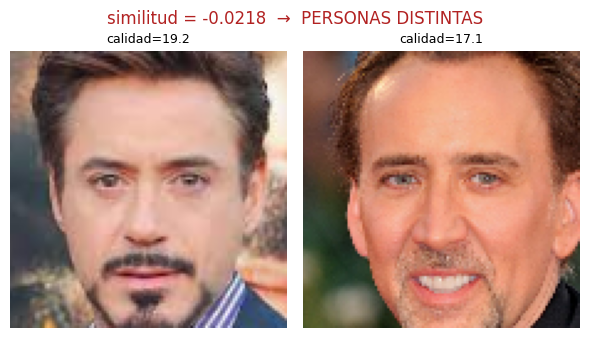

similitud = -0.0218   (umbral = 0.3)   ->   ❌ PERSONAS DISTINTAS


In [ ]:
mostrar_par(img2, img3)
verificar(img2, img3);

## 8. Matriz de similitud completa

En lugar de comparar pares sueltos, calculamos **todos contra todos** y lo mostramos como un mapa de calor. Es la forma compacta de ver el comportamiento del sistema: la **diagonal** vale 1 (cada rostro consigo mismo), el **bloque** de las dos fotos de Robert Downey Jr. debería destacar con valores altos, y las comparaciones con Nicolas Cage deberían quedar bajas.

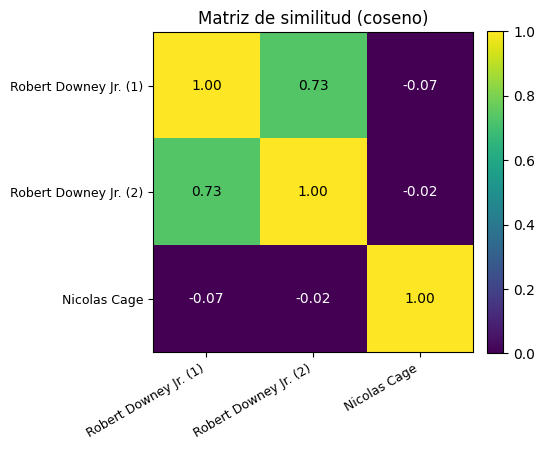

In [ ]:
# Calculamos los embeddings una sola vez
nombres = list(rutas.keys())
embs = [obtener_embedding(r)[0] for r in rutas.values()]

# Matriz de similitud coseno (n x n)
n = len(embs)
M = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        M[i, j] = similitud(embs[i], embs[j])

# Mapa de calor
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(M, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels(nombres, rotation=30, ha='right', fontsize=9)
ax.set_yticklabels(nombres, fontsize=9)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f'{M[i, j]:0.2f}', ha='center', va='center',
                color='white' if M[i, j] < 0.6 else 'black', fontsize=10)
ax.set_title('Matriz de similitud (coseno)')
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 9. Experimento: robustez frente a la calidad de la imagen

Aquí está la **idea central de AdaFace**. Vamos a tomar el rostro de Robert Downey Jr. (`img1`), **degradarlo progresivamente** (desenfoque + reducción de resolución, como una foto de cámara de seguridad) y, en cada nivel, medir dos cosas:

1. La **norma / calidad** que estima AdaFace para la cara degradada.
2. La **similitud** contra la otra foto suya (`img2`), que dejamos intacta.

Lo interesante: a medida que la imagen empeora, **la calidad estimada cae** —AdaFace lo "nota"— y, aun así, la similitud se mantiene razonablemente alta antes de derrumbarse. Eso es justamente lo que el margen adaptativo busca: no exigirle lo imposible a una imagen pobre.

In [ ]:
def degradar(cara_pil, factor):
    '''Degrada una cara alineada: la reduce a 1/factor y la reescala de vuelta
    (pierde detalle, como una foto de baja resolución). factor=1 no cambia nada.'''
    if factor <= 1:
        return cara_pil
    w, h = cara_pil.size
    chica = cara_pil.resize((max(1, w // factor), max(1, h // factor)), Image.BILINEAR)
    return chica.resize((w, h), Image.BILINEAR)

# Partimos de la cara YA alineada de img1, y la foto de referencia (img2)
_, _, cara_ref = obtener_embedding(img1)
emb_ref2, _, _  = obtener_embedding(img2)

factores = [1, 2, 4, 8, 12, 16]
calidades, similitudes, miniaturas = [], [], []
for f in factores:
    cara_deg = degradar(cara_ref, f)
    emb_deg, norma_deg = _embedding_de_cara(cara_deg)
    calidades.append(norma_deg)
    similitudes.append(similitud(emb_deg, emb_ref2))
    miniaturas.append(cara_deg)

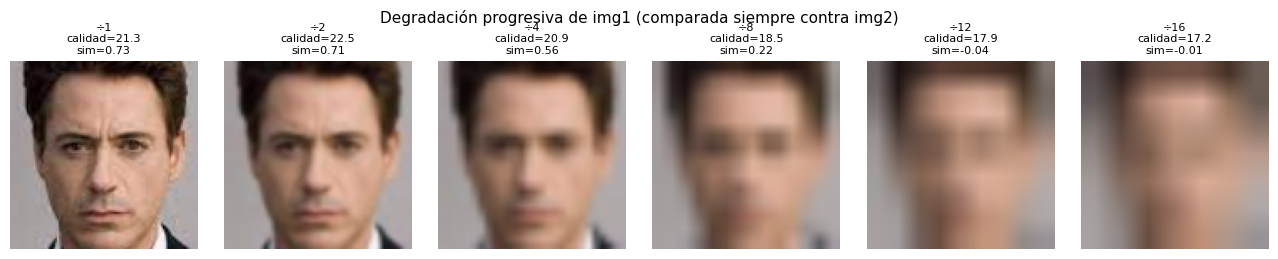

In [ ]:
# Mostramos las versiones degradadas
fig, ax = plt.subplots(1, len(factores), figsize=(13, 2.6))
for a, f, cara, q, s in zip(ax, factores, miniaturas, calidades, similitudes):
    a.imshow(cara); a.axis('off')
    a.set_title(f'÷{f}\ncalidad={q:0.1f}\nsim={s:0.2f}', fontsize=8)
fig.suptitle('Degradación progresiva de img1 (comparada siempre contra img2)', fontsize=11)
plt.tight_layout(); plt.show()

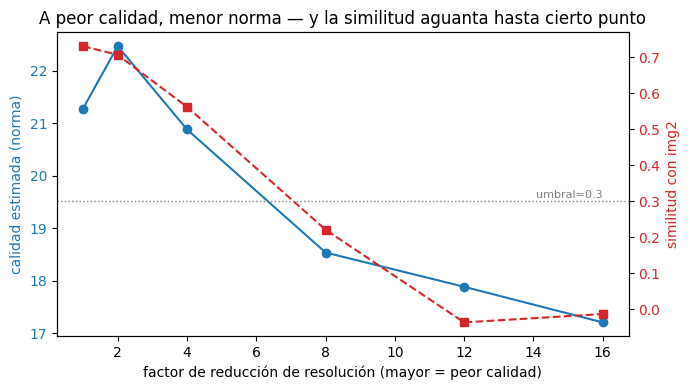

In [ ]:
# Graficamos cómo evolucionan calidad y similitud con la degradación
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(factores, calidades, 'o-', color='tab:blue', label='calidad (norma)')
ax1.set_xlabel('factor de reducción de resolución (mayor = peor calidad)')
ax1.set_ylabel('calidad estimada (norma)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(factores, similitudes, 's--', color='tab:red', label='similitud con img2')
ax2.axhline(UMBRAL, color='gray', ls=':', lw=1)
ax2.set_ylabel('similitud con img2', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.text(factores[-1], UMBRAL + 0.01, f'umbral={UMBRAL}', ha='right', fontsize=8, color='gray')

plt.title('A peor calidad, menor norma — y la similitud aguanta hasta cierto punto')
plt.tight_layout(); plt.show()

## 10. Identificación 1:N (¿quién es esta persona?)

Hasta ahora hicimos **verificación 1:1** (¿son la misma persona estas dos fotos?). El otro gran modo de uso es la **identificación 1:N**: tenemos una **galería** de personas conocidas (inscritas previamente) y llega una foto **sonda**; el sistema debe decir a quién se parece más.

Inscribimos una galería con Robert Downey Jr. (`img1`) y Nicolas Cage (`img3`), y usamos como sonda la **segunda** foto de Robert Downey Jr. (`img2`), que el sistema no tiene inscrita. El resultado esperado es que la identifique como Robert Downey Jr.

In [ ]:
# Galería de personas conocidas (nombre -> embedding inscrito)
galeria = {
    'Robert Downey Jr.': obtener_embedding(img1)[0],
    'Nicolas Cage'     : obtener_embedding(img3)[0],
}

def identificar(path_sonda, galeria, umbral=UMBRAL):
    '''Compara la sonda contra toda la galería y devuelve el ranking.'''
    emb_sonda, _, _ = obtener_embedding(path_sonda)
    ranking = sorted(
        ((nombre, similitud(emb_sonda, emb)) for nombre, emb in galeria.items()),
        key=lambda t: t[1], reverse=True
    )
    mejor, mejor_s = ranking[0]
    print('Ranking de coincidencias:')
    for nombre, s in ranking:
        print(f'   {nombre:20s}  sim = {s:0.4f}')
    if mejor_s >= umbral:
        print(f'\n>> Identificada como: {mejor} (sim = {mejor_s:0.4f})')
    else:
        print(f'\n>> Desconocida: ninguna coincidencia supera el umbral ({umbral})')
    return ranking

# Sonda: la otra foto de Robert Downey Jr.
identificar(img2, galeria);

Ranking de coincidencias:
   Robert Downey Jr.     sim = 0.7305
   Nicolas Cage          sim = -0.0218

>> Identificada como: Robert Downey Jr. (sim = 0.7305)


---
*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">03_Identificar_Cara.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">